In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv('attrition.csv')

In [17]:
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Attrition'] = df['Attrition'].map({'No': 0, 'Yes': 1})

X = df[['Age','Gender','JobSatisfaction','MonthlyIncome']]
y = df['Attrition']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 32
Test size: 8


In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
model = LogisticRegression(solver="lbfgs", max_iter=1000)
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [21]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

In [22]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.875

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.80      0.89         5
           1       0.75      1.00      0.86         3

    accuracy                           0.88         8
   macro avg       0.88      0.90      0.87         8
weighted avg       0.91      0.88      0.88         8



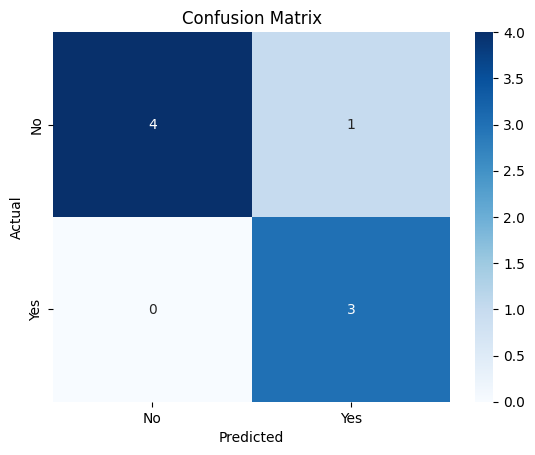

In [23]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No","Yes"], yticklabels=["No","Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [24]:
results = X_test.copy()
results['Actual'] = y_test.values
results['Predicted'] = y_pred
results['Pred_Prob'] = np.round(y_prob, 3)

results.reset_index(drop=True, inplace=True)
print(results)

   Age  Gender  JobSatisfaction  MonthlyIncome  Actual  Predicted  Pred_Prob
0   36       0                4           7000       0          0      0.253
1   35       0                3           6800       0          1      0.582
2   33       1                3           5600       0          0      0.450
3   31       1                2           3300       1          1      0.936
4   41       1                5          10200       0          0      0.002
5   27       1                3           3900       1          1      0.789
6   34       1                4           6400       0          0      0.118
7   28       0                2           3400       1          1      0.986
